In [50]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

--- Missing Values Summary ---
                                     Missing Values  Percentage (%)
PresentWeather(rank)                          32441       57.692376
MaximumWindSpeed(m/s)                           741        1.317778
MinimumWindSpeed(m/s)                           741        1.317778
WindSpeed(m/s)                                  618        1.099038
WindDirection(deg)                              501        0.890968
MaximumPrecipitationIntensity(mm/h)             321        0.570859
PrecipitationAmount(mm)                         303        0.538849
RelativeHumidity(%)                             289        0.513951
AirPressure(hPa)                                210        0.373459
AirTemperature(degC)                            208        0.369903
HighestTemperature(degC)                        203        0.361011
LowestTemperature(degC)                         203        0.361011
Latitude                                        191        0.339670
Longitude        

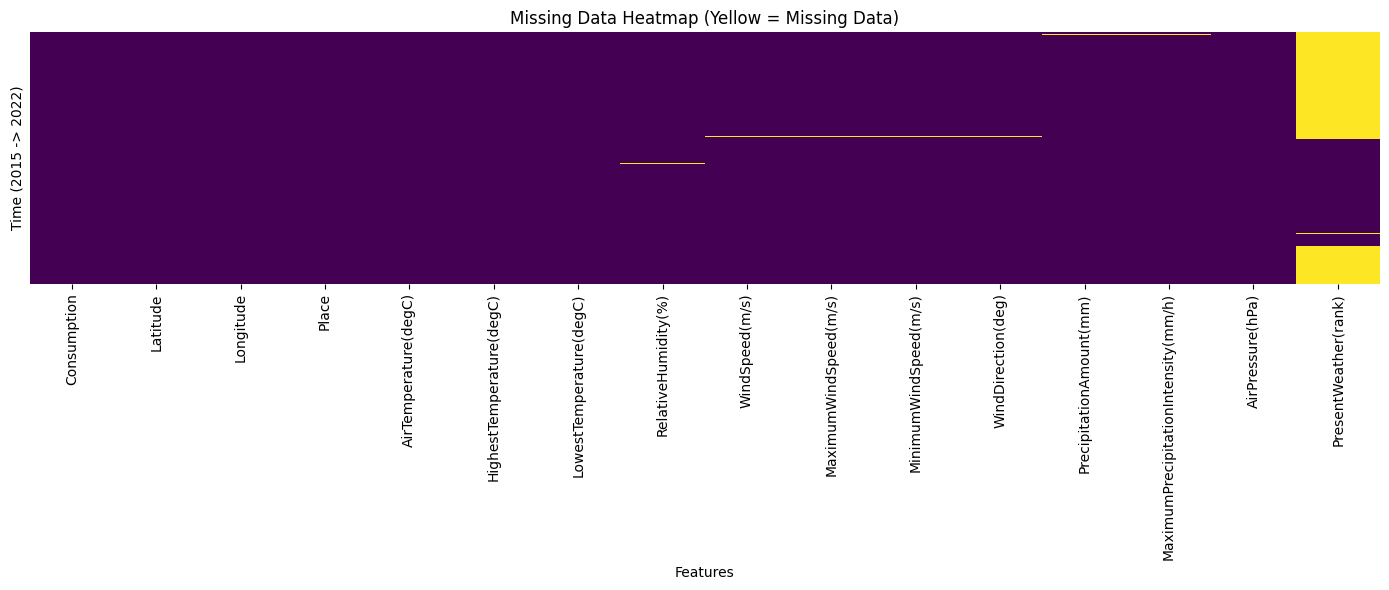

In [70]:
# Load the dataset
df = pd.read_csv('dataset_mansion.csv',index_col=0)

# Fix column types that pandas misread, so the rest of the exploration is accurate:
# - 'Consumption' uses a comma as decimal separator -> loaded as text, needs to become float
# - 'MTime' is a timestamp string -> parse to datetime so we can explore the time range
# _ Set 'MTime' as the index so we can easily explore time-based patterns
df['Consumption'] = df['Consumption'].str.replace(',', '.', regex=False).astype(float)
df['MTime'] = pd.to_datetime(df['MTime'])
df.set_index('MTime', inplace=True)

# Align the timeline
# Resample to a strict hourly frequency ('h'). 
# If a specific hour is completely missing from the CSV, this forces pandas to insert a blank row for it.
df_aligned = df.asfreq('h')

# Quantify Missing Values
missing_counts = df_aligned.isna().sum()
missing_percentages = (missing_counts / len(df_aligned)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_counts,
    'Percentage (%)': missing_percentages
}).sort_values(by='Missing Values', ascending=False)

print("--- Missing Values Summary ---")
#print(missing_summary)
print(missing_summary[missing_summary['Missing Values'] > 0])

# Visualize Missing Data
# A heatmap where solid colors represent data, and bright lines represent missing values (NaN)
plt.figure(figsize=(14, 6))
sns.heatmap(df_aligned.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Data Heatmap (Yellow = Missing Data)')
plt.xlabel('Features')
plt.ylabel('Time (2015 -> 2022)')
plt.tight_layout()
plt.show()

# # For each day and feature, count missing hourly values
# daily_missing = df_aligned.isna().resample('D').sum()

# plt.figure(figsize=(14, 7))
# sns.heatmap(
#     daily_missing,
#     cmap='viridis',
#     vmin=0,
#     vmax=24,
#     yticklabels=False,
#     cbar_kws={'label': 'Missing hours per day'}
# )
# plt.title('Missing Data by Day')
# plt.xlabel('Features')
# plt.ylabel('Time: earliest at top, latest at bottom')
# plt.tight_layout()
# plt.show()

/var/folders/0t/k860jmxx4d5__9h3p08nh77m0000gn/T/ipykernel_54696/1089432416.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_by_year = df_aligned.groupby('Year').apply(lambda x: (x.isna().sum() / len(x)) * 100)


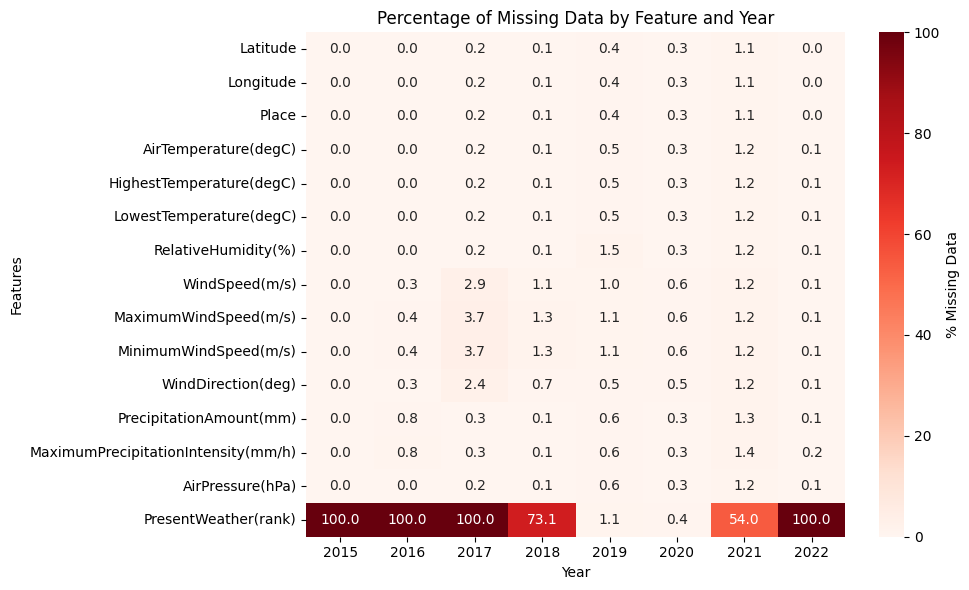

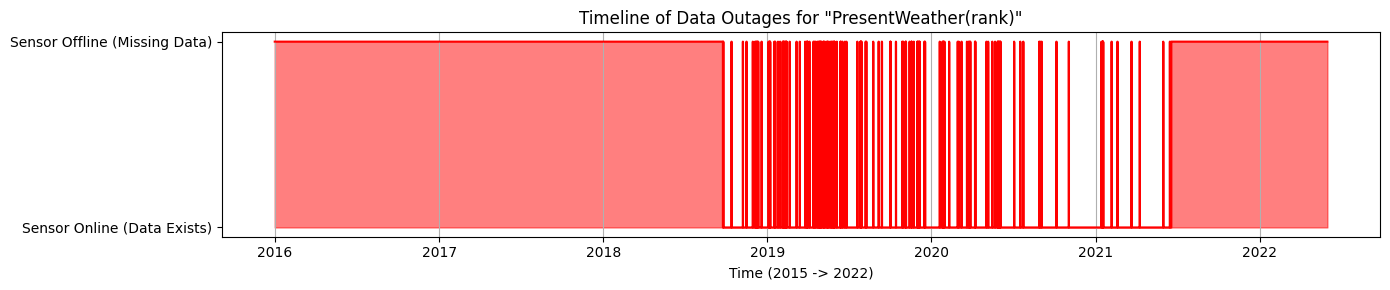

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# (Assuming df_aligned is already created from the previous step)
# df_aligned = df.asfreq('H')

# --- Visualization 1: Percentage of Missing Data by Year ---

# Calculate percentage of missing data per year
df_aligned['Year'] = df_aligned.index.year
missing_by_year = df_aligned.groupby('Year').apply(lambda x: (x.isna().sum() / len(x)) * 100)

# Clean up: Drop the 'Year' column, transpose it so years are on the X-axis, 
# and filter out columns that have 0 missing data
missing_by_year = missing_by_year.drop(columns=['Year']).T
missing_by_year = missing_by_year.loc[(missing_by_year > 0).any(axis=1)]

plt.figure(figsize=(10, 6))
# Plot a heatmap with the actual percentages written inside the boxes
sns.heatmap(missing_by_year, annot=True, fmt=".1f", cmap="Reds", cbar_kws={'label': '% Missing Data'})
plt.title('Percentage of Missing Data by Feature and Year')
plt.xlabel('Year')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


# --- Visualization 2: Timeline of Major Sensor Outages ---

# Create a binary column: 1 if missing, 0 if available
weather_rank = df_aligned[['PresentWeather(rank)']].copy()
weather_rank['Missing_Status'] = weather_rank['PresentWeather(rank)'].isna().astype(int)

plt.figure(figsize=(14, 3))
# Plot a step chart to show exactly when the data drops out
plt.fill_between(weather_rank.index, weather_rank['Missing_Status'], color='red', alpha=0.5, step="pre")
plt.plot(weather_rank.index, weather_rank['Missing_Status'], color='red', drawstyle="steps-pre")

plt.title('Timeline of Data Outages for "PresentWeather(rank)"')
plt.yticks([0, 1], ['Sensor Online (Data Exists)', 'Sensor Offline (Missing Data)'])
plt.xlabel('Time (2015 -> 2022)')
plt.grid(axis='x')
plt.tight_layout()
plt.show()

# Drop the temporary Year column so it doesn't interfere with later steps
df_aligned.drop(columns=['Year'], inplace=True)

In [54]:
print(df.isnull().sum()) # check for missing values

Consumption                                0
Latitude                                 191
Longitude                                191
Place                                    191
AirTemperature(degC)                     208
HighestTemperature(degC)                 203
LowestTemperature(degC)                  203
RelativeHumidity(%)                      289
WindSpeed(m/s)                           618
MaximumWindSpeed(m/s)                    741
MinimumWindSpeed(m/s)                    741
WindDirection(deg)                       501
PrecipitationAmount(mm)                  303
MaximumPrecipitationIntensity(mm/h)      321
AirPressure(hPa)                         210
PresentWeather(rank)                   32441
dtype: int64


In [55]:
# Correlation between numeric features (helps spot which weather variables
# relate to Consumption and which weather columns duplicate each other)

corr = df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns)
fig.colorbar(im, ax=ax, label='Correlation')
ax.set_title('Correlation matrix of numeric features')
plt.tight_layout()
plt.show()

print(corr['Consumption'].sort_values(ascending=False))

ValueError: could not convert string to float: 'Jyväskylä lentoasema'